# Elderly concentration and access to acute hospitals in Singapore

**Research question.** How does spatial clustering of elderly populations correlate with access to
healthcare services? By analysing geographical demographics, travel time by public transport, and
the financial limitations of the elderly, we assess whether existing health facilities are adequately
distributed and sufficiently accessible for an ageing society.

This notebook answers the question with methods covered in the course: summary tables and plotnine
charts, correlation and chi-square tests, and, as reference models, OLS and logit with marginal effects.

---
### Read this first (for the team)

**Which notebook is which?**

| File | What it is | Do you need to run it? |
|---|---|---|
| `elderly_access_course_methods.ipynb` (this one) | The main analysis, using only methods covered in the course | Yes |
| `elderly_healthcare_access.ipynb` | The earlier version. It **builds the data table** this notebook uses, and also tries spatial statistics (Moran's I, LISA) that are **not** covered in class | No, keep for reference. Its output is already saved in `data/processed/` |
| `summary_stats.ipynb` | Our census cleaning notebook | Separate |

**How to run this notebook.**
1. Activate the course virtual environment.
2. Install the packages once: `pip install -r requirements.txt`. Besides the usual packages (pandas, plotnine,
   scipy, statsmodels, stargazer, marginaleffects) this adds **geopandas**, which is only used to read the
   map file for the two maps.
3. Open this notebook from the repository folder (so the `data/` paths work) and *Run All*.

**Folders**
* `data/raw/`: the original downloaded data (census, boundaries, hospital list, OpenStreetMap layers).
* `data/processed/`: `subzone_elderly_access.csv`, the one table this notebook analyses.
* `output/figures/` and `output/tables/`: saved charts and tables. Tables from this notebook start with `course_`.

**Glossary**
* **Subzone / planning area / region.** URA divides Singapore into 5 regions, 55 planning areas and 332
  subzones (e.g. region *North-East* → planning area *Ang Mo Kio* → subzone *Cheng San*). Our unit of analysis
  (one row of data) is the **subzone**, the smallest area with published census counts.
* **Acute hospital.** A hospital that provides emergency and specialist care, as listed by MOH: 11 public
  (including KK Women's and Children's Hospital and the Institute of Mental Health) and 9 private.
* **OpenStreetMap (OSM).** A free, volunteer-made world map, like Wikipedia for maps. We used it to locate
  the hospitals, bus stops, MRT/LRT stations and residential buildings. We downloaded it with **oex**, an
  open-source tool that exports OSM data for one country.
* **Straight-line distance.** Distance "as the crow flies", ignoring roads. We use it as a simple stand-in
  (proxy) for travel time.
* **Elderly-weighted average.** An average in which each subzone counts in proportion to how many elderly
  live there, so a subzone with 10,000 elderly counts more than one with 100.

**How the data table was made** (done in `elderly_healthcare_access.ipynb`, not here):
1. *Census.* From the SingStat file we added up residents aged 65+ in each subzone (`pop65`) and divided by
   all residents (`pct65`).
2. *Where elderly live.* We do not know each person's address, so we spread each subzone's elderly over the
   residential buildings in that subzone (bigger buildings get more people).
3. *Distance.* For every building we measured the straight-line distance to the nearest acute hospital, then
   took the average for the subzone, weighting each building by its number of elderly. This gives
   `dist_km_any`, and the same for the nearest **public** hospital (`dist_km_public`).
4. *Public transport.* A building "has PT access" if a bus stop or MRT/LRT station is within 400 m.
   `pct_pt_access` is the % of a subzone's elderly living in such buildings; `pop65_no_pt` counts those who don't.

**Operationalisation**

| Concept | Measure | Variable |
|---|---|---|
| Elderly | Residents aged 65+ per subzone (SingStat, June 2026) | `pop65`, `pct65` |
| Healthcare services | The 20 MOH acute hospitals, public and private (MOH, 2026) | |
| Travel time (proxy) | Straight-line distance from where elderly live to the nearest acute hospital, km | `dist_km_any` |
| Affordable option | Straight-line distance to the nearest *public* acute hospital, km | `dist_km_public` |
| Public transport access | % of elderly with a bus stop or MRT/LRT station within 400 m of home | `pct_pt_access` |

**Data.** One row per residential subzone. The table was built in `elderly_healthcare_access.ipynb` from
the census, URA subzone boundaries, the MOH hospital list and OpenStreetMap layers; distances are
averaged over the homes of the elderly in each subzone.

**Which subzones are included.** Singapore has 332 subzones. We keep the **212 with at least 1,000
residents**, which hold 99.7% of residents aged 65+. The 120 excluded subzones are:
* 91 with no residents (industrial estates, water catchment, ports),
* 12 with residents but no elderly,
* 17 small subzones with 2,110 elderly in total (0.26%). Their percentages are unstable, and some are
  dominated by nursing homes (e.g. Loyang West: 520 of 530 residents are 65+).

Every kept subzone has at least 50 elderly residents.

### Setup
The usual imports, plus `geopandas` (read map shapes) and `Path` (build file paths that work on
both Mac and Windows).

In [1]:
%pip install -r requirements.txt

import warnings
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import plotnine as p9
from scipy import stats

warnings.filterwarnings("ignore")

RAW = Path("data/raw")
PROCESSED = Path("data/processed")
FIGURES = Path("output/figures")
TABLES = Path("output/tables")


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /Users/jialinwu/Documents/hs4002_ay26/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 1. Load the subzone data

We read only the columns we need (`usecols`) and make a shorter region name, e.g. `"NORTH-EAST REGION"` →
`"North-East"`. Each row is one subzone; there should be 212 rows.

In [2]:
cols = ["planning_area", "subzone", "REGION_N", "pop", "pop65", "pct65", "dist_km_any", "nearest_any",
        "dist_km_public", "nearest_public", "pct_pt_access", "pop65_no_pt"]
df = pd.read_csv(PROCESSED / "subzone_elderly_access.csv", usecols=cols)
df["region"] = df.REGION_N.str.replace(" REGION", "").str.title()
print(df.shape)
df.head()

(212, 13)


,REGION_N,planning_area,subzone,pop,pop65,pct65,pct_pt_access,pop65_no_pt,dist_km_any,nearest_any,dist_km_public,nearest_public,region
0,CENTRAL REGION,Bukit Merah,Depot Road,6400,1210,18.906250,100.0,0.0,1.186290,Alexandra Hospital,1.186290,Alexandra Hospital,Central
1,CENTRAL REGION,Bukit Merah,Bukit Merah,1050,320,30.476190,100.0,0.0,1.596406,Alexandra Hospital,1.596406,Alexandra Hospital,Central
2,CENTRAL REGION,Outram,Chinatown,9990,2350,23.523524,100.0,0.0,0.710415,Singapore General Hospital,0.710415,Singapore General Hospital,Central
3,CENTRAL REGION,Outram,China Square,1290,510,39.534884,100.0,0.0,1.230187,Singapore General Hospital,1.230187,Singapore General Hospital,Central
4,CENTRAL REGION,Bukit Merah,Tiong Bahru,12190,2760,22.641509,100.0,0.0,0.903958,Singapore General Hospital,0.903958,Singapore General Hospital,Central


## 2. Descriptive statistics

`describe()` gives the count, mean, standard deviation, minimum, quartiles and maximum of each variable,
and we add **skewness** (positive = long tail to the right, negative = long tail to the left).

In [3]:
summary = df[["pct65", "pop65", "dist_km_any", "dist_km_public", "pct_pt_access"]].describe().T
summary["skew"] = df[summary.index].skew()
summary = summary.round(2)
summary.to_csv(TABLES / "course_descriptives.csv")
summary

,count,mean,std,min,25%,50%,75%,max,skew
pct65,212.0,20.02,6.87,1.92,15.39,20.52,24.70,39.53,-0.06
pop65,212.0,3892.03,3756.08,50.00,1140.00,2870.00,5527.50,28540.00,2.39
dist_km_any,212.0,2.22,1.33,0.31,1.20,1.88,3.06,6.26,0.87
dist_km_public,212.0,2.64,1.44,0.38,1.48,2.32,3.71,6.26,0.57
pct_pt_access,212.0,98.14,6.85,53.35,100.00,100.00,100.00,100.00,-4.59


**What we found.** On average 20% of a subzone's residents are 65+ (from 2% to 40%). The average
straight-line distance to the nearest acute hospital is 2.2 km (0.3 to 6.3 km); it is 2.6 km if only public
hospitals count. PT access is almost always 100% (183 of 212 subzones), which is why it is so skewed
(skew = −4.6): this measure barely varies.

Next we plot the distributions. `melt()` turns the four columns into one long column so that plotnine can
draw one histogram per variable with `facet_wrap`.

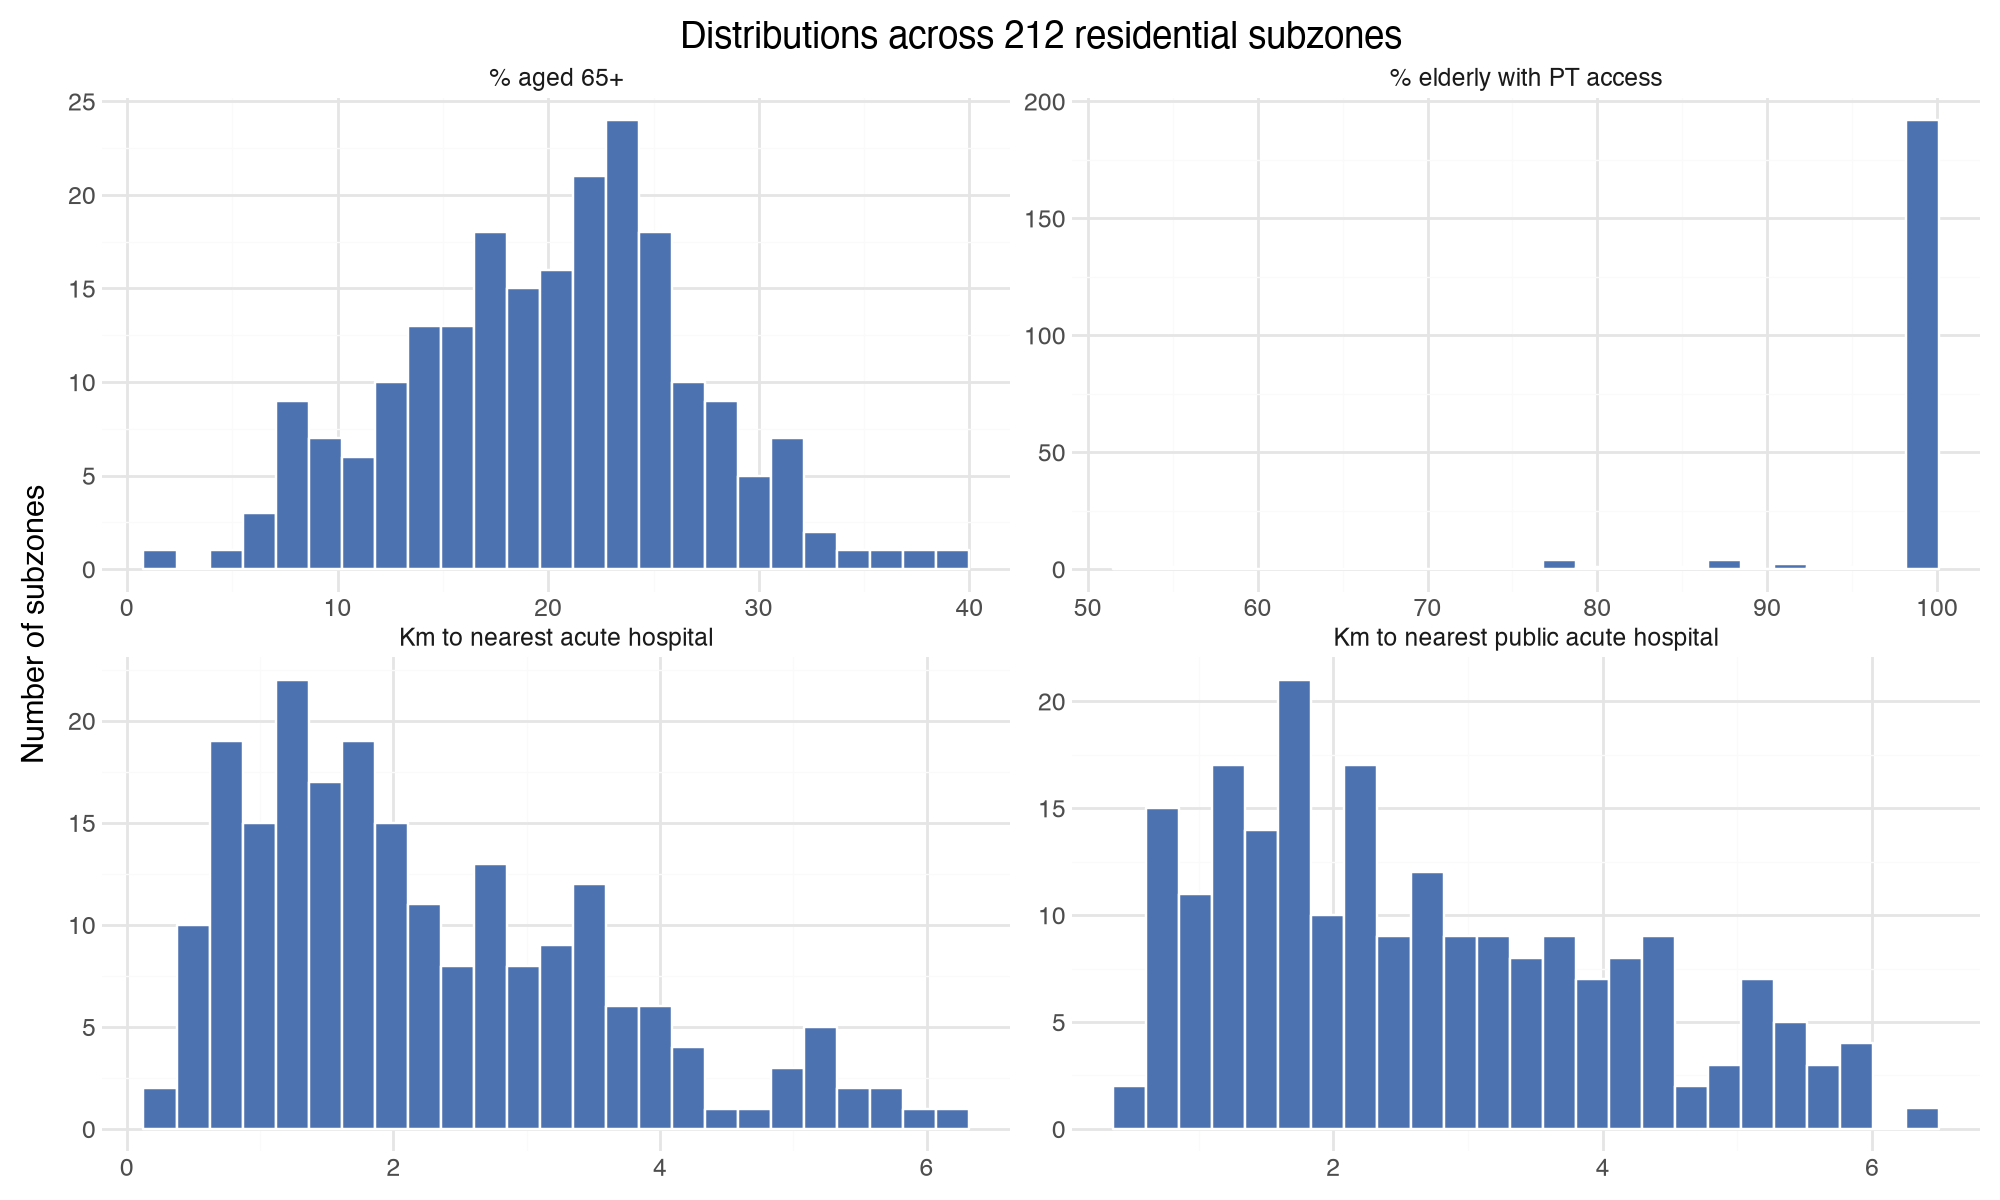

In [4]:
long = df.melt(value_vars=["pct65", "dist_km_any", "dist_km_public", "pct_pt_access"])
labels = {"pct65": "% aged 65+", "dist_km_any": "Km to nearest acute hospital",
          "dist_km_public": "Km to nearest public acute hospital", "pct_pt_access": "% elderly with PT access"}
long["variable"] = long.variable.map(labels)
(
    p9.ggplot(long, p9.aes("value"))
    + p9.geom_histogram(bins=25, fill="#4c72b0", color="white")
    + p9.facet_wrap("~variable", scales="free")
    + p9.labs(x="", y="Number of subzones", title="Distributions across 212 residential subzones")
    + p9.theme_minimal()
    + p9.theme(figure_size=(10, 6))
)

## 3. Where are the elderly concentrated?

Our research question asks about the **spatial clustering** of the elderly. We describe it in two ways:
1. a **map** of the share of residents aged 65+, with acute hospitals marked;
2. a **comparison of the five regions**: is a **high-elderly subzone** (top quarter of `pct65`, i.e. 24.7% or
   more) more common in some regions than others? We test this with a **chi-square test of independence**
   and measure its strength with **Cramér's V**.

*Not covered in class:* drawing maps. The map file is read with `geopandas.read_file` (like `pd.read_csv`,
but each row also has a shape), then joined to our table with `merge` on a `key` made of planning area +
subzone name. plotnine draws the shapes with `geom_map`, which works like any other `geom_`.

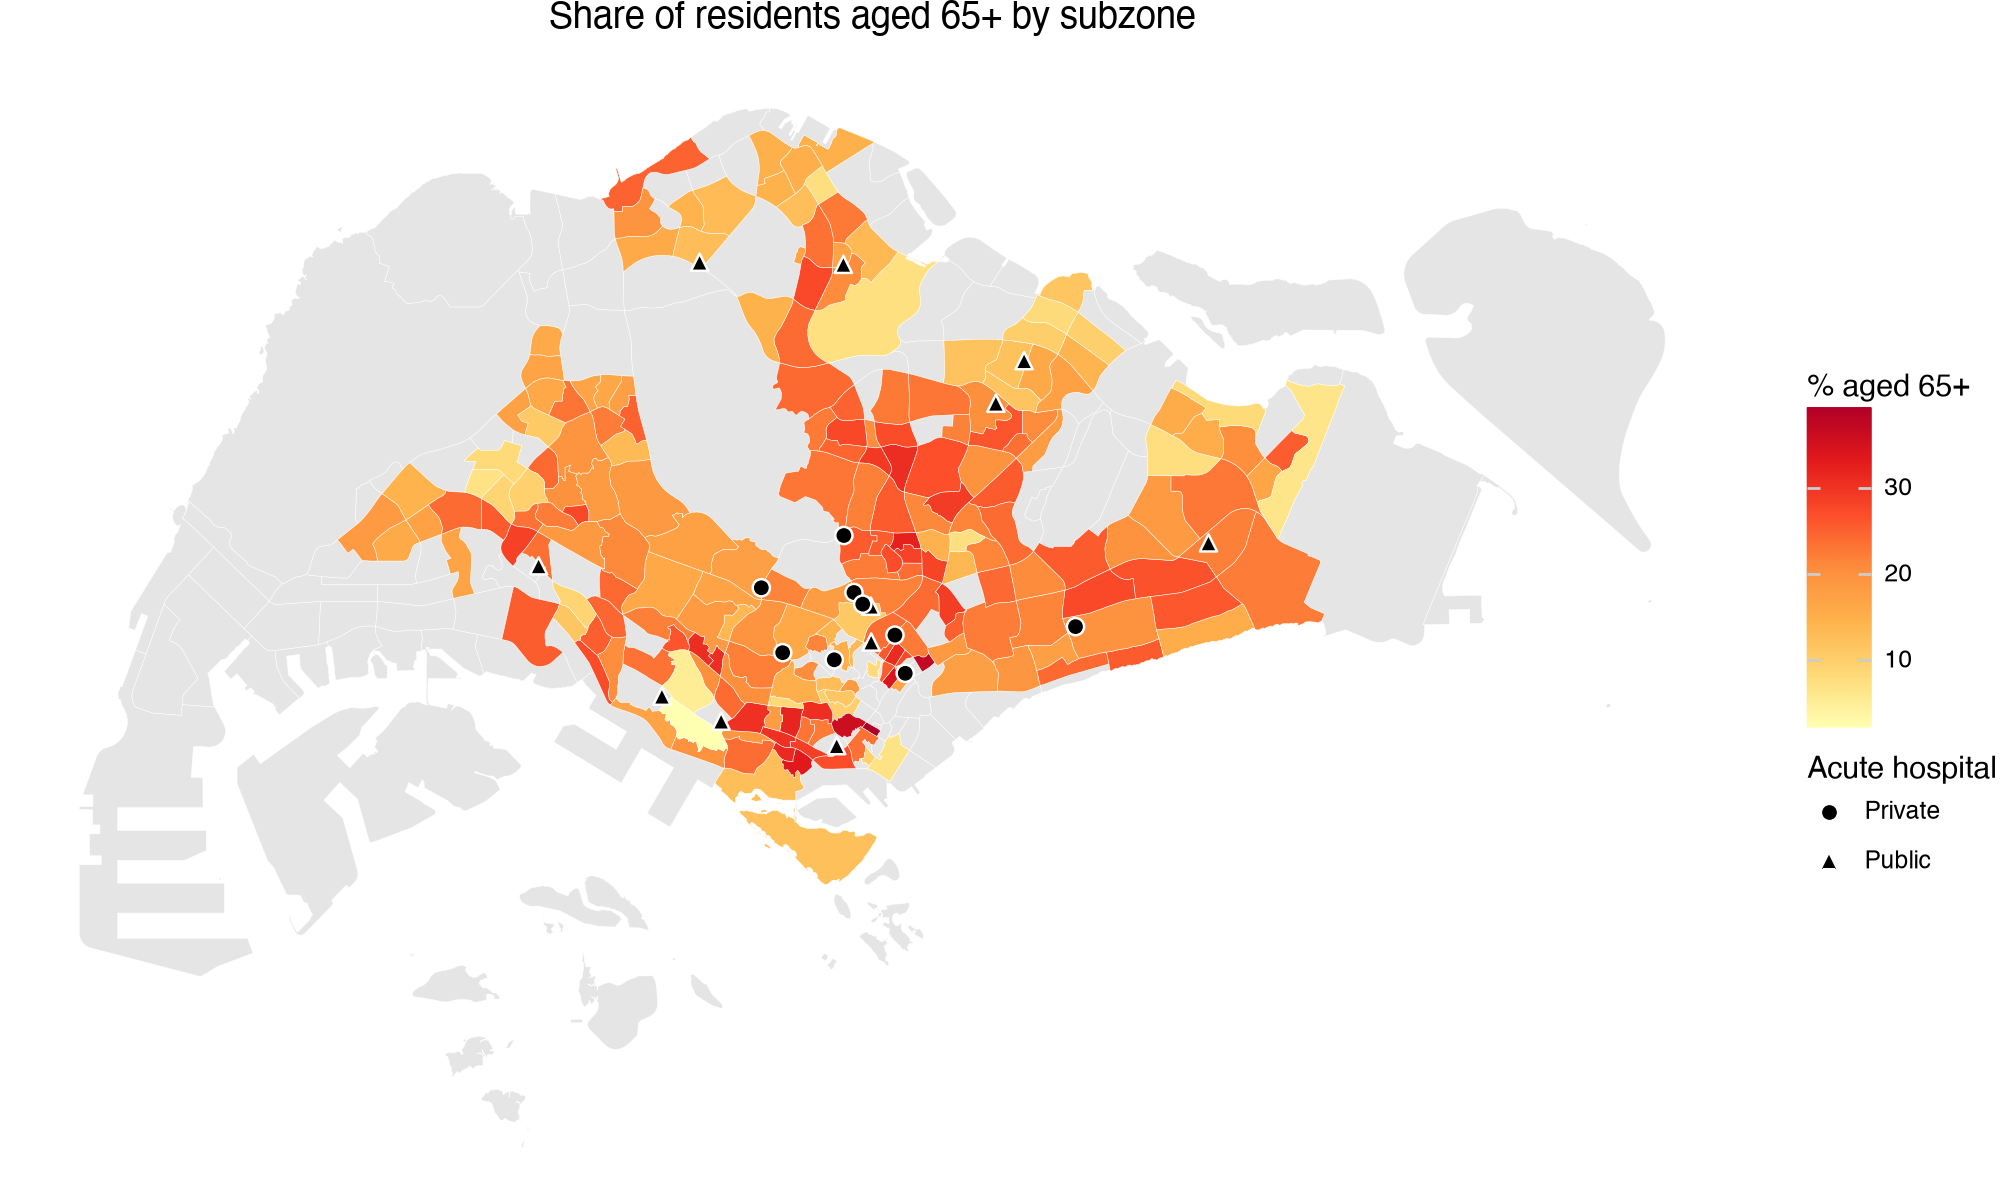

In [5]:
subzones = gpd.read_file(RAW / "mp2019_subzone_no_sea.geojson")
subzones["key"] = subzones.PLN_AREA_N + "|" + subzones.SUBZONE_N
df["key"] = df.planning_area.str.upper() + "|" + df.subzone.str.upper()
geo = subzones.merge(df, on="key", how="left")

hospitals = gpd.read_file(RAW / "oex" / "oex_sgp_acute_hospitals_osm.geojson").merge(
    pd.read_csv(RAW / "moh_acute_hospitals.csv"), left_on="id", right_on="osm_id")
hospitals["geometry"] = hospitals.to_crs(3414).representative_point().to_crs(4326)
hospitals["x"], hospitals["y"] = hospitals.geometry.x, hospitals.geometry.y


def subzone_map(column, title, fill_label):
    return (
        p9.ggplot()
        + p9.geom_map(geo[geo[column].isna()], fill="#e5e5e5", color="white", size=0.1)
        + p9.geom_map(geo[geo[column].notna()], p9.aes(fill=column), color="white", size=0.1)
        + p9.geom_point(hospitals, p9.aes("x", "y", shape="sector"), size=3, fill="black", color="white")
        + p9.scale_fill_distiller(palette="YlOrRd", direction=1)
        + p9.labs(title=title, fill=fill_label, shape="Acute hospital")
        + p9.theme_void()
        + p9.theme(figure_size=(10, 6))
    )


subzone_map("pct65", "Share of residents aged 65+ by subzone", "% aged 65+")

**Reading the map.** Grey areas are the excluded subzones (no or very few residents). Darker red = a higher
share of elderly. Triangles are public and circles private acute hospitals. The darkest subzones are
in older estates in and around the centre (Outram, Bukit Merah, Kallang, Rochor, Toa Payoh, Ang Mo Kio),
close to where many hospitals are. Newer towns such as Punggol, Sengkang, Tengah and Sembawang are lighter.

Explain the assumption later lmao (in more detail -- these places need access the most?)

The table below summarises each region with `groupby().agg()`.

In [6]:
region_table = df.groupby("region").agg(
    subzones=("subzone", "size"),
    residents_65plus=("pop65", "sum"),
    mean_pct65=("pct65", "mean"),
    median_pct65=("pct65", "median"),
).round(1).sort_values("mean_pct65", ascending=False)
region_table.to_csv(TABLES / "course_elderly_by_region.csv")
region_table

,subzones,residents_65plus,mean_pct65,median_pct65
region,,,,
Central,94,221420,21.3,21.7
North-East,34,180780,20.5,21.7
East,20,149020,19.4,20.0
West,42,178480,18.8,18.5
North,22,95410,16.6,14.8


In [7]:
df["high_elderly"] = np.where(df.pct65 >= df.pct65.quantile(0.75), "High elderly", "Other")
crosstab = pd.crosstab(df.region, df.high_elderly)
chi2, p, dof, expected = stats.chi2_contingency(crosstab)
cramers_v = stats.contingency.association(crosstab, method="cramer")
print(crosstab, "\n")
print(f"Chi-square = {chi2:.2f}, df = {dof}, p = {p:.4f}, Cramér's V = {cramers_v:.2f}")
print(f"Smallest expected count: {expected.min():.1f} (chi-square needs about 5 or more)")

high_elderly  High elderly  Other
region                           
Central                 28     66
East                     6     14
North                    2     20
North-East              10     24
West                     7     35 

Chi-square = 6.29, df = 4, p = 0.1783, Cramér's V = 0.17
Smallest expected count: 5.0 (chi-square needs about 5 or more)


**How to read the chi-square test.** The null hypothesis is that being a high-elderly subzone is unrelated
to region. A small p-value (below 0.05) would mean high-elderly subzones are concentrated in some regions.
Cramér's V runs from 0 (no association) to 1 (perfect association).

**What we found.** The Central region has the largest number of high-elderly subzones (28 of 94, 30%; the East
has the same share, 6 of 20), and the North the fewest (2 of 22, 9%). But the test is **not significant** (χ² = 6.29, df = 4, p = 0.18) and the association is
weak (Cramér's V = 0.17). So the map shows elderly concentrated in older central estates, but at the level of
whole regions the difference could be due to chance. The smallest expected count is 5.0, right at the
usual minimum, so the test is valid but only just.

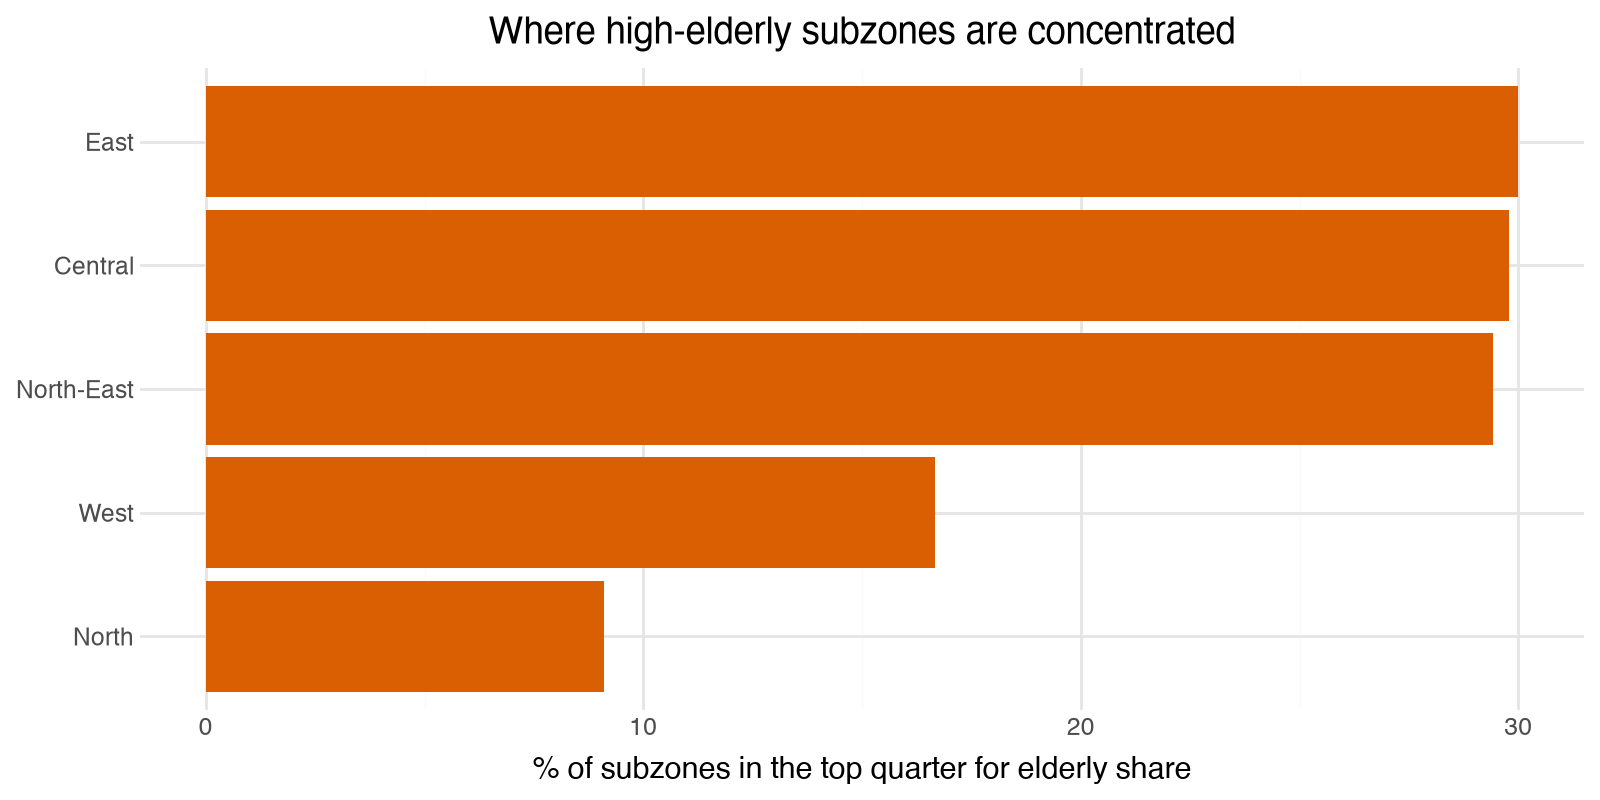

In [8]:
share = (crosstab["High elderly"] / crosstab.sum(axis=1) * 100).rename("pct").reset_index()
(
    p9.ggplot(share, p9.aes(x="reorder(region, pct)", y="pct"))
    + p9.geom_col(fill="#d95f02")
    + p9.coord_flip()
    + p9.labs(x="", y="% of subzones in the top quarter for elderly share",
              title="Where high-elderly subzones are concentrated")
    + p9.theme_minimal()
    + p9.theme(figure_size=(8, 4))
)

## 4. How accessible are acute hospitals?

Now the access side of the question: how far do the elderly live from an acute hospital, and can they
reach public transport?

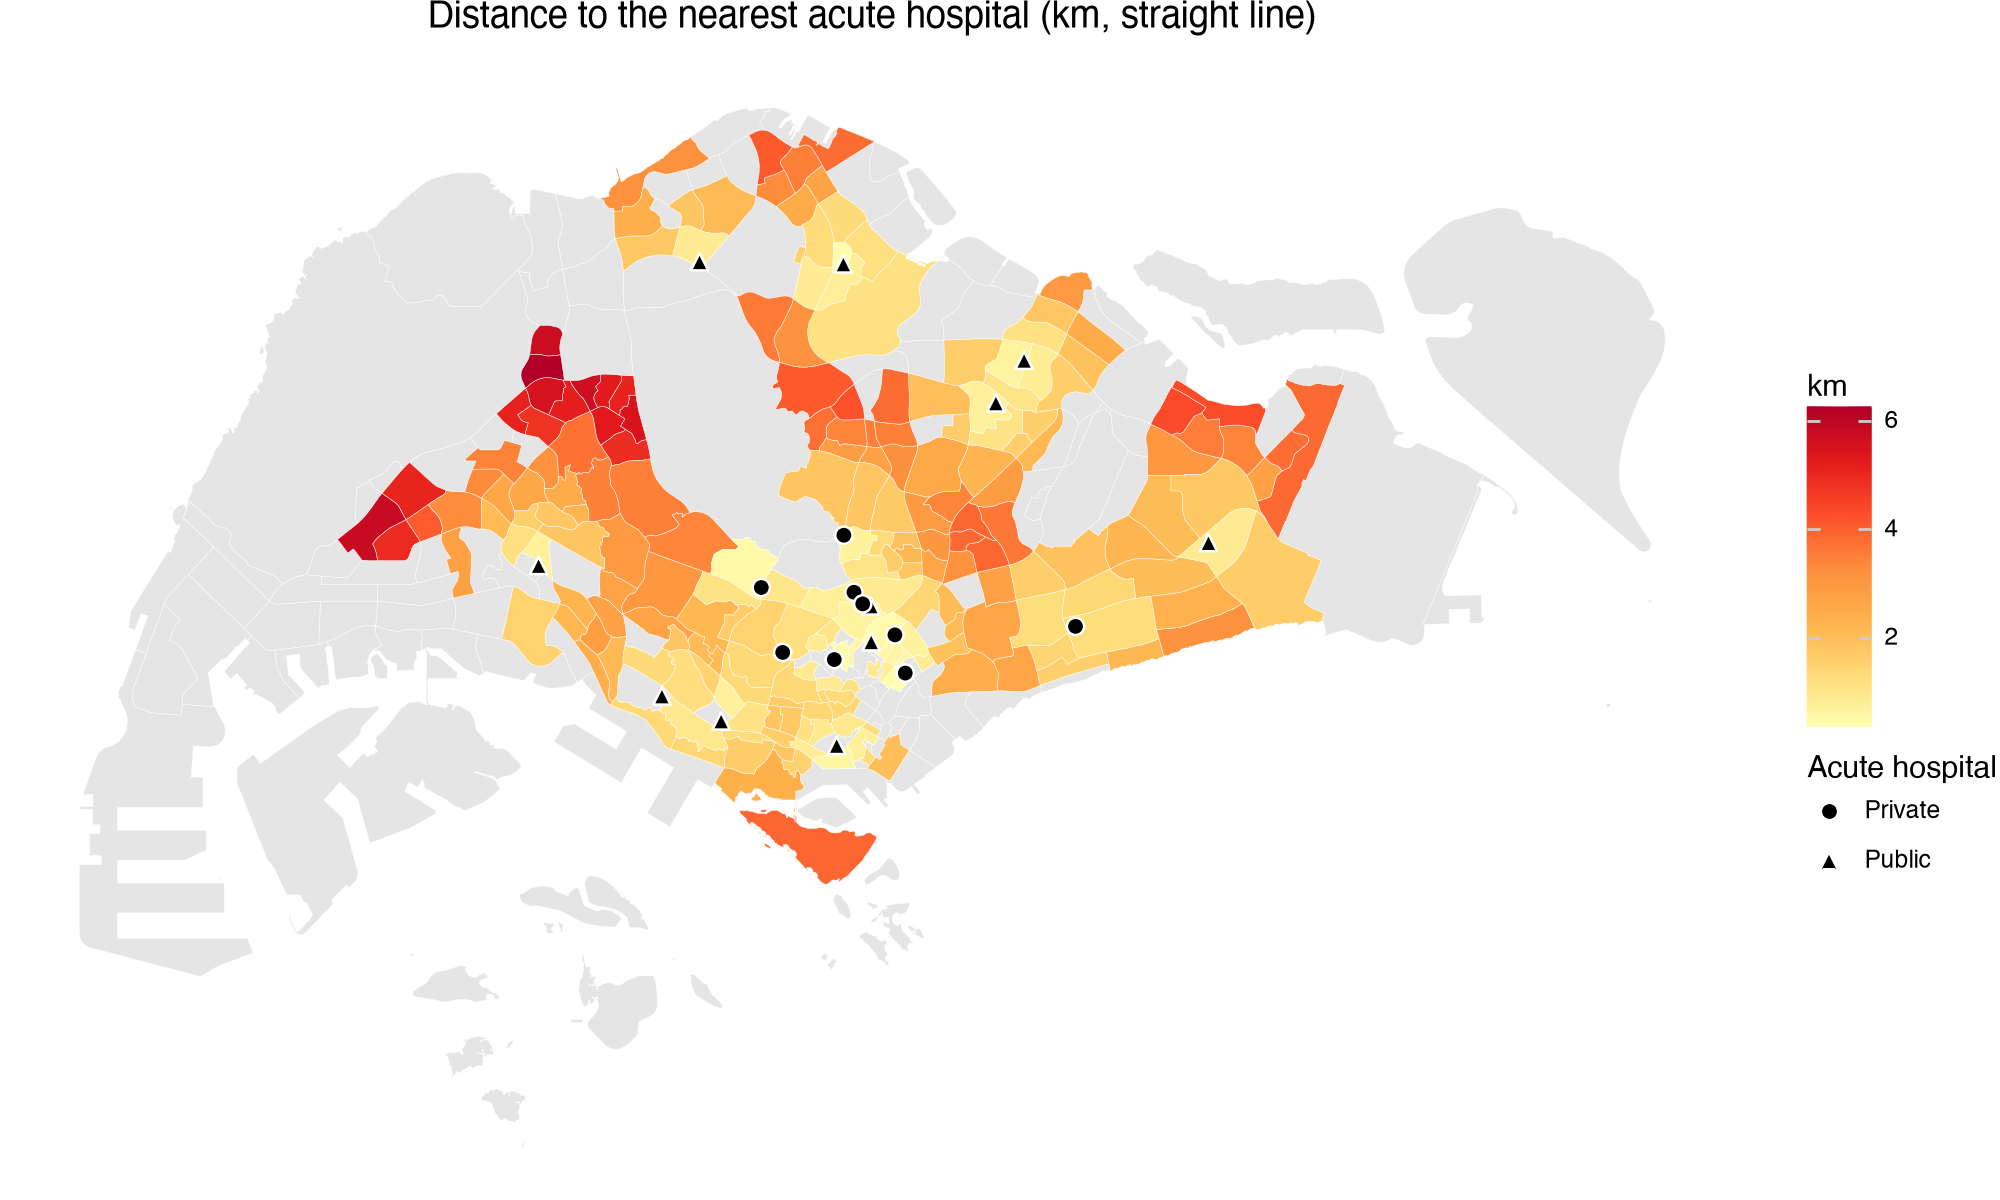

In [9]:
subzone_map("dist_km_any", "Distance to the nearest acute hospital (km, straight line)", "km")

**Reading the map.** Darker = further from the nearest acute hospital. The 12 furthest subzones (more than
5 km) are all in the West: Choa Chu Kang, Bukit Panjang and Jurong West.

Next we group subzones into distance bands. `pd.cut` turns a number into categories (like recoding age into
age groups), then we add up the elderly in each band.

In [10]:
bands = pd.cut(df.dist_km_any, [0, 1, 2, 3, 5, np.inf], labels=["< 1 km", "1-2 km", "2-3 km", "3-5 km", "> 5 km"])
access_bands = df.groupby(bands).agg(subzones=("subzone", "size"), residents_65plus=("pop65", "sum"))
access_bands["pct_of_elderly"] = (100 * access_bands.residents_65plus / df.pop65.sum()).round(1)
access_bands.to_csv(TABLES / "course_elderly_by_distance_band.csv")
access_bands

,subzones,residents_65plus,pct_of_elderly
dist_km_any,,,
< 1 km,37,99320,12.0
1-2 km,73,293930,35.6
2-3 km,47,229410,27.8
3-5 km,43,139270,16.9
> 5 km,12,63180,7.7


**What we found.** 47.6% of elderly live in subzones that are on average within 2 km of an acute hospital,
75.4% within 3 km. 7.7% (about 63,000 elderly) live in subzones more than 5 km away.

The next cell uses `np.average(..., weights=...)` for an **elderly-weighted average** (see glossary), so the
answer describes the typical elderly *person* rather than the typical subzone.

In [11]:
no_pt = df.pop65_no_pt.sum()
print(f"Elderly without a stop within 400 m of home: {no_pt:,.0f} ({100 * no_pt / df.pop65.sum():.1f}% of elderly)")
print(f"Elderly-weighted mean distance to nearest acute hospital: {np.average(df.dist_km_any, weights=df.pop65):.2f} km")
print(f"Elderly-weighted mean distance to nearest public acute hospital: {np.average(df.dist_km_public, weights=df.pop65):.2f} km")

Elderly without a stop within 400 m of home: 4,927 (0.6% of elderly)
Elderly-weighted mean distance to nearest acute hospital: 2.33 km
Elderly-weighted mean distance to nearest public acute hospital: 2.74 km


In [12]:
access_by_region = df.groupby("region").apply(lambda g: pd.Series({
    "km_any": np.average(g.dist_km_any, weights=g.pop65),
    "km_public": np.average(g.dist_km_public, weights=g.pop65),
    "pct_pt_access": np.average(g.pct_pt_access, weights=g.pop65),
})).round(2)
access_by_region

,km_any,km_public,pct_pt_access
region,,,
Central,1.62,2.58,98.71
East,2.13,2.68,99.91
North,1.81,1.81,99.85
North-East,2.22,2.47,99.46
West,3.77,3.77,99.54


**What we found.**
* Only about 4,900 elderly (0.6%) have no bus stop or MRT/LRT station within 400 m of home. By our
  definition, public transport access is nearly universal.
* The typical elderly person lives 2.3 km from the nearest acute hospital, or 2.7 km if they need a public
  one.
* The **West** stands out: its elderly live on average 3.8 km away, more than twice the Central region (1.6 km).
  In the Central region the nearest hospital is often private; the nearest public one is 2.6 km away.

The averages above hide how much subzones differ *within* each region. A **boxplot** (`geom_boxplot`) shows
the median (middle line), the middle 50% of subzones (the box) and the range (the whiskers).
We also draw every subzone as a dot with `geom_jitter`, which is `geom_point` with a small random sideways
shift so the dots don't sit on top of each other. Each dot is sized by its number of residents aged 65+.

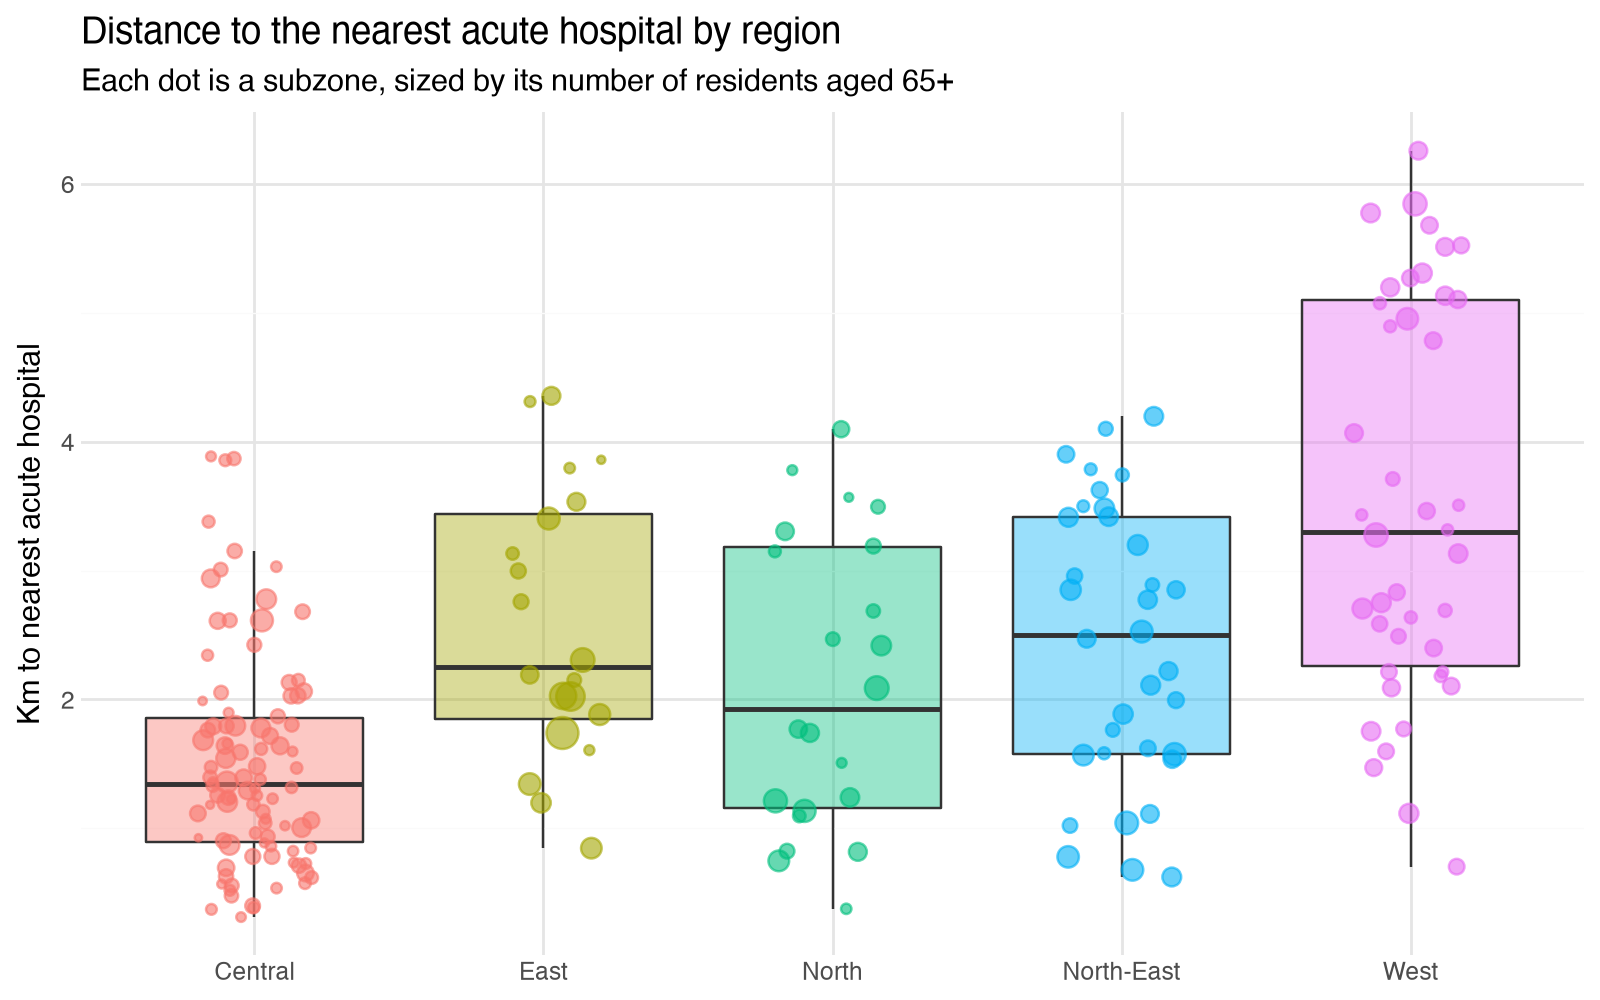

In [13]:
(
    p9.ggplot(df, p9.aes("region", "dist_km_any", fill="region"))
    + p9.geom_boxplot(outlier_shape="", alpha=0.4, show_legend=False)
    + p9.geom_jitter(p9.aes(size="pop65", color="region"), width=0.2, alpha=0.6, random_state=4002,
                     show_legend=False)
    + p9.labs(x="", y="Km to nearest acute hospital",
              title="Distance to the nearest acute hospital by region",
              subtitle="Each dot is a subzone, sized by its number of residents aged 65+")
    + p9.theme_minimal()
    + p9.theme(figure_size=(8, 5))
)

**What we found.** The Central region is consistently close: half its subzones are within 1.3 km of an acute
hospital and none is more than 3.9 km away. The West has the highest median (3.3 km) and the widest spread,
from 0.7 km to 6.3 km, so even within the West some subzones are close to a hospital and others are far.
The East, North and North-East sit in between (medians 1.9–2.5 km).

## 5. Does elderly concentration correlate with access?

This is the core of the research question. We use **Spearman's rank correlation** rather than
Pearson's, because the count of elderly, distance and PT access are skewed (section 2) and we only expect
"more of one, more (or less) of the other", not a straight line.

**How to read it.** `rho` runs from −1 to +1. A positive `rho` between elderly share and distance would mean
*more elderly → further from hospital* (worse access); a negative one means *more elderly → closer*. As a
rough guide, |rho| below 0.3 is weak. Neighbouring subzones tend to be similar, so they are not fully
independent observations; treat the p-values as a rough guide.

In [14]:
pairs = []
for x, x_label in [("pct65", "% aged 65+"), ("pop65", "Residents aged 65+")]:
    for y, y_label in [("dist_km_any", "Km to nearest acute hospital"),
                       ("dist_km_public", "Km to nearest public acute hospital"),
                       ("pct_pt_access", "% elderly with PT access")]:
        d = df[[x, y]].dropna()
        rho, p = stats.spearmanr(d[x], d[y])
        pairs.append({"x": x_label, "y": y_label, "rho": round(rho, 3), "p": round(p, 4), "n": len(d)})
correlations = pd.DataFrame(pairs)
correlations.to_csv(TABLES / "course_spearman.csv", index=False)
correlations

,x,y,rho,p,n
0,% aged 65+,Km to nearest acute hospital,-0.139,0.0431,212
1,% aged 65+,Km to nearest public acute hospital,-0.079,0.2548,212
2,% aged 65+,% elderly with PT access,0.143,0.0369,212
3,Residents aged 65+,Km to nearest acute hospital,0.164,0.0171,212
4,Residents aged 65+,Km to nearest public acute hospital,0.145,0.0352,212
5,Residents aged 65+,% elderly with PT access,0.236,0.0005,212


**What we found.** All correlations are **weak** (|rho| ≤ 0.24).
* Elderly share vs distance to any acute hospital: rho = −0.14 (p = 0.04). Subzones with more elderly are
  slightly *closer* to a hospital, the opposite of what an access problem would look like.
* Elderly share vs distance to a *public* hospital: rho = −0.08 (p = 0.25), no relationship.
* Subzones with more elderly *residents* (a count, not a share) are slightly further from hospitals
  (rho = 0.16) but have slightly better PT access (rho = 0.24). These are mostly large HDB towns.

The scatterplot shows the same thing; the black line is a straight-line fit with its confidence band
(`geom_smooth(method="lm")`). Colour shows region: most far-away subzones are in the West.

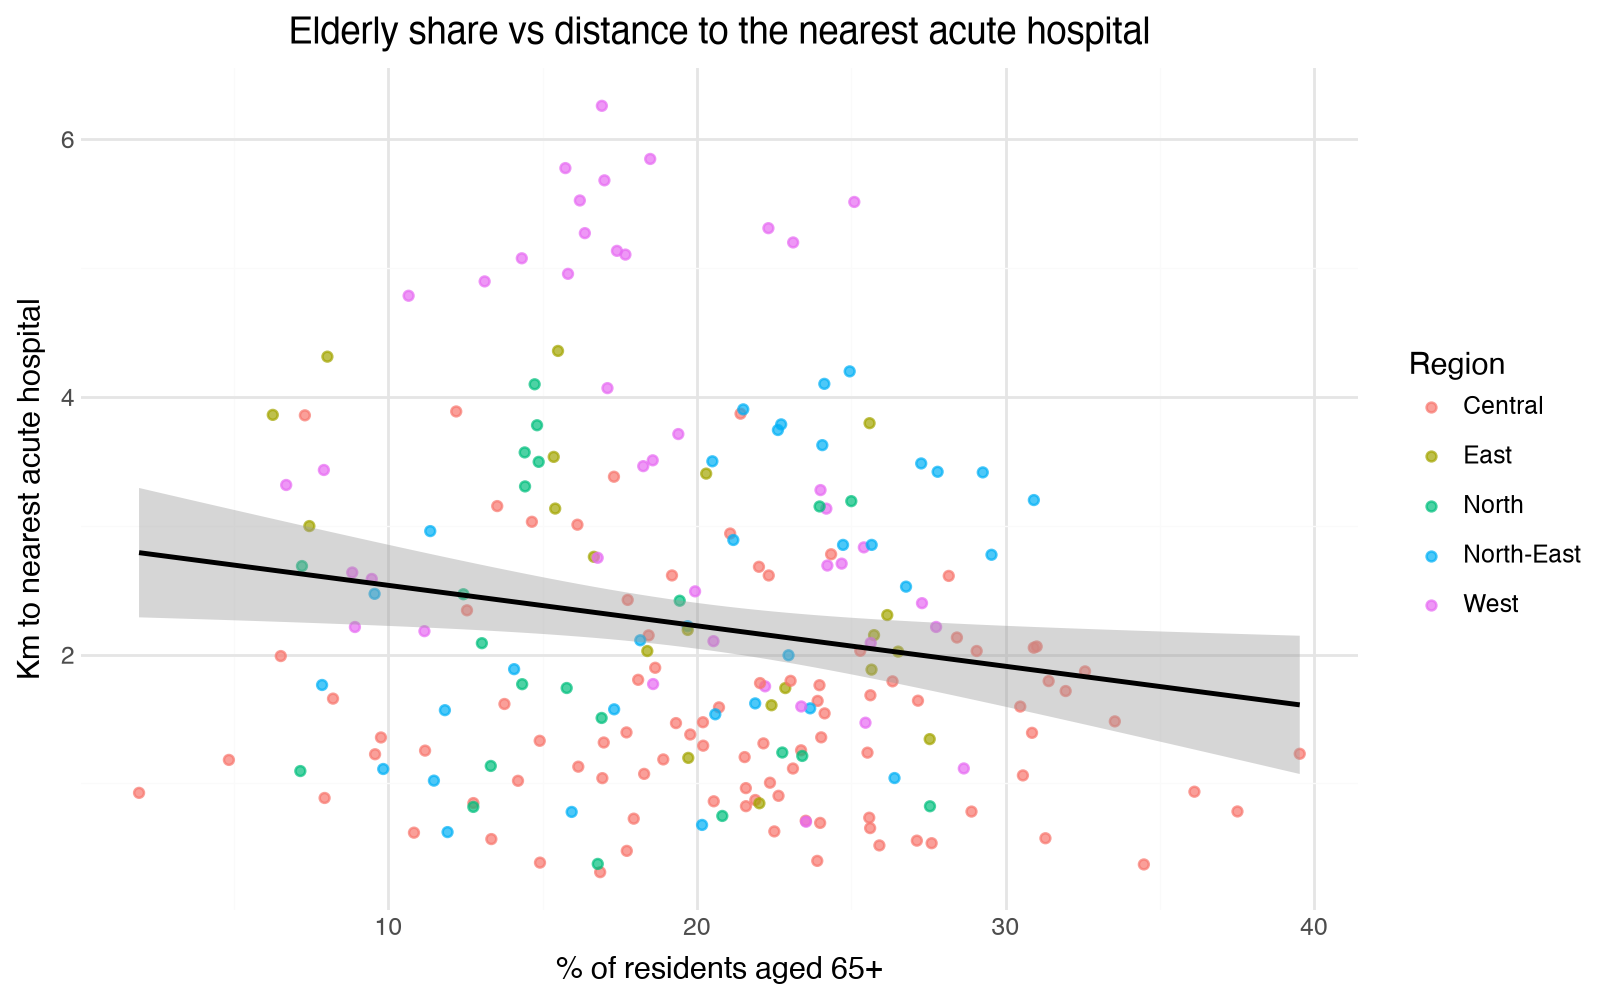

In [15]:
(
    p9.ggplot(df, p9.aes("pct65", "dist_km_any"))
    + p9.geom_point(p9.aes(color="region"), alpha=0.7)
    + p9.geom_smooth(method="lm", color="black")
    + p9.labs(x="% of residents aged 65+", y="Km to nearest acute hospital", color="Region",
              title="Elderly share vs distance to the nearest acute hospital")
    + p9.theme_minimal()
    + p9.theme(figure_size=(8, 5))
)

## 6. Reference models: OLS and logit

Correlations look at two variables at a time. Regression lets us look at the elderly share while
**holding other things constant** (controls). We include these models **for reference**:
they support the correlation results above rather than replace them.

The models use all **212 subzones**.

### 6a. OLS: distance to the nearest acute hospital

We build the models step by step:
* **Model 1:** `dist_km_any ~ pct65` (elderly share only)
* **Model 2:** + `region`. Region is a category, so statsmodels turns it into dummy variables (0/1 variables,
  one per region). **Central is the reference group**: each region's coefficient is how many km further
  (or closer) its subzones are compared with Central.

`pd.Categorical(..., categories=[...])` simply fixes the order of the regions so that Central comes first and
becomes the reference group.

In [16]:
import statsmodels.formula.api as smf
from marginaleffects import avg_slopes
from stargazer.stargazer import Stargazer
from statsmodels.stats.anova import anova_lm

mdf = df.copy()
mdf["region"] = pd.Categorical(mdf.region, categories=["Central", "East", "North", "North-East", "West"])
print(f"Model sample: {len(mdf)} subzones")

lm1 = smf.ols("dist_km_any ~ pct65", data=mdf).fit()
lm2 = smf.ols("dist_km_any ~ pct65 + region", data=mdf).fit()
print(lm2.summary())

Model sample: 212 subzones
                            OLS Regression Results                            
Dep. Variable:            dist_km_any   R-squared:                       0.344
Model:                            OLS   Adj. R-squared:                  0.328
Method:                 Least Squares   F-statistic:                     21.57
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           2.42e-17
Time:                        15:22:33   Log-Likelihood:                -315.63
No. Observations:                 212   AIC:                             643.3
Df Residuals:                     206   BIC:                             663.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Inter

**How to read Model 2.** Each coefficient is the change in km for a one-unit change in that variable,
holding the others constant. For example, the West coefficient (1.99) means West subzones are on average
1.99 km further from an acute hospital than Central subzones with the same elderly share.

Next we compare the two models with R², adjusted R² and AIC: higher (adjusted) R² and lower AIC
= better model.

In [17]:
ols_comparison = pd.DataFrame({
    "Model": ["Model 1", "Model 2"],
    "R-Squared": [lm1.rsquared, lm2.rsquared],
    "Adj. R-Squared": [lm1.rsquared_adj, lm2.rsquared_adj],
    "AIC": [lm1.aic, lm2.aic],
}).round(2)
ols_comparison

,Model,R-Squared,Adj. R-Squared,AIC
0,Model 1,0.03,0.02,718.86
1,Model 2,0.34,0.33,643.27


In [18]:
# F-test for nested models: does adding region improve the fit?
print(anova_lm(lm1, lm2))

   df_resid         ssr  df_diff    ss_diff          F        Pr(>F)
0     210.0  361.648682      0.0        NaN        NaN           NaN
1     206.0  243.806392      4.0  117.84229  24.892202  7.956043e-17


**What we found.**
* **On its own, the elderly share is significant but explains very little.** In Model 1, each extra percentage
  point of elderly goes with a subzone 0.031 km *closer* to a hospital (p = 0.02), but R² is only 0.026.
* **Once region is added, the elderly share is no longer significant** (Model 2: −0.017 km per point,
  p = 0.12). Older subzones looked closer mainly because many of them are in the Central region, near the
  hospitals.
* Adding **region** improves the model a lot: R² rises from 0.03 to 0.34, AIC drops from 719 to 643, and the
  F-test is highly significant (p < 0.001). All four regions are significantly further from hospitals than
  Central; the West most (+1.99 km), then East (+1.03 km), North-East (+0.92 km) and North (+0.54 km).

The regression table below is made with `Stargazer`, ready to paste into Overleaf. Numbers in
brackets are standard errors; stars show significance.

In [19]:
LABELS = {
    "pct65": "% aged 65+",
    "region[T.East]": "East (vs Central)",
    "region[T.North]": "North (vs Central)",
    "region[T.North-East]": "North-East (vs Central)",
    "region[T.West]": "West (vs Central)",
    "Intercept": "Intercept",
}
sg = Stargazer([lm1, lm2])
sg.title("Distance to the nearest acute hospital (km)")
sg.dependent_variable_name("Km to nearest acute hospital")
sg.custom_columns(["Model 1", "Model 2"], [1, 1])
sg.covariate_order(list(LABELS))
sg.rename_covariates(LABELS)
sg

### 6b. Logit: is a subzone far from an acute hospital?

A second way to ask the same question, with a **yes/no outcome**: is a subzone **far** from an acute
hospital? `far` = 1 when its elderly live on average more than **3 km** (straight line) from the nearest
acute hospital, otherwise 0. The 3 km cut-off is our choice; it is close to the top quarter of distances
(3.06 km). 55 of the 212 subzones are far.

We use the same two steps as the OLS models, and compare them with **AIC** and the **likelihood-ratio
(LR) test**. A small LR p-value means the bigger model fits significantly better.

In [20]:
mdf["far"] = (mdf.dist_km_any > 3).astype(int)
print(f"Far subzones: {mdf.far.sum()} of {len(mdf)}")
print(pd.crosstab(mdf.region, mdf.far))

lg1 = smf.logit("far ~ pct65", data=mdf).fit(disp=0)
lg2 = smf.logit("far ~ pct65 + region", data=mdf).fit(disp=0)
print(lg2.summary())

Far subzones: 55 of 212
far          0   1
region            
Central     87   7
East        13   7
North       15   7
North-East  23  11
West        19  23
                           Logit Regression Results                           
Dep. Variable:                    far   No. Observations:                  212
Model:                          Logit   Df Residuals:                      206
Method:                           MLE   Df Model:                            5
Date:                Wed, 28 Oct 2026   Pseudo R-squ.:                  0.1696
Time:                        15:22:33   Log-Likelihood:                -100.78
converged:                       True   LL-Null:                       -121.36
Covariance Type:            nonrobust   LLR p-value:                 8.658e-08
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -1.6644  

In [21]:
for name, m in [("Logit 1", lg1), ("Logit 2", lg2)]:
    print(f"AIC {name}: {m.aic:.2f}")

lr_stat = 2 * (lg2.llf - lg1.llf)
df_diff = lg2.df_model - lg1.df_model
print(f"Logit 1 vs 2: LR statistic = {lr_stat:.2f}, df = {df_diff:.0f}, p-value = {stats.chi2.sf(lr_stat, df_diff):.4f}")

AIC Logit 1: 241.69
AIC Logit 2: 213.55
Logit 1 vs 2: LR statistic = 36.14, df = 4, p-value = 0.0000


In [22]:
sg = Stargazer([lg1, lg2])
sg.title("Probability that a subzone is more than 3 km from an acute hospital (logit)")
sg.dependent_variable_name("Far from hospital")
sg.custom_columns(["Logit 1", "Logit 2"], [1, 1])
sg.covariate_order(list(LABELS))
sg.rename_covariates(LABELS)
sg

In [23]:
# Average marginal effect: change in the probability of being far for a 1-point increase
avg_slopes(lg2, variables=["pct65"])

term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""pct65""","""dY/dX""",-0.0066,0.004248,-1.553902,0.121743,3.038092,-0.014975,0.001774


**How to read this.** Logit coefficients (in the table above) are in log-odds, which are hard to interpret.
The **average marginal effect** converts them into probabilities: the `Estimate` is how much the
probability of being far changes when the elderly share goes up by 1 percentage point, averaged over all subzones.

**What we found.** The logit tells the same story as the OLS.
* On its own (Logit 1), a higher elderly share makes a subzone slightly *less* likely to be far (p = 0.03).
* Adding region improves the model a lot (LR p < 0.001; AIC falls from 242 to 214), and the elderly share is
  then **not significant**: a 1-point higher elderly share changes the probability of being far by
  −0.7 percentage points (p = 0.12).
* Region matters: 23 of 42 West subzones are far, compared with 7 of 94 in the Central region.

## 7. Summary of findings

1. **Clustering.** The elderly are concentrated in older estates around the centre, but at the level of the five
   regions the difference is not statistically significant (chi-square p = 0.18).
2. **Access is generally good by our measures.** The typical elderly person lives 2.3 km (straight line) from an
   acute hospital, and 99.4% live within 400 m of a bus stop or MRT/LRT station.
3. **Elderly concentration does not go with worse access.** The correlation is weak and slightly negative
   (more elderly → slightly closer), and once region is controlled for, the elderly share is not significant
   in the OLS or logit models.
4. **Where you live matters more than how many elderly live there.** Region explains most of the differences in
   distance (R² from 0.03 to 0.34). The **West** is furthest from acute hospitals (3.8 km on average).
5. **Public vs private.** The nearest acute hospital is often private; the nearest public one is 0.4 km further
   on average (2.7 vs 2.3 km), and about 1 km further in the Central region.

## 8. Limitations

* **Straight-line distance stands in for travel time.** It ignores routes, waiting and transfers.
* **PT access only checks the home end** and almost every elderly resident passes it (stop within 400 m),
  so it varies little between subzones.
* **Nearest hospital** includes KK Women's and Children's Hospital and the Institute of Mental Health, which
  do not serve most elderly acute needs, and private hospitals, which cost more.
* **Regions are a coarse way to describe clustering**: they show broad concentration, not exact clusters.
* **Subzone averages** hide differences between individuals (ecological fallacy).
* **Excluded subzones.** Small subzones (under 1,000 residents, 2,110 elderly) are left out.
* **OLS assumptions.** Model 2's residuals are not normal and their spread is uneven (heteroskedastic),
  so its standard errors are approximate.
* **The logit outcome** depends on the 3 km cut-off.
* **No financial measure.** This notebook does not measure the financial limitations named in the research
  question; the public-vs-private hospital comparison only touches on affordability.